Random Forest

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn import datasets

In [ ]:
iris=datasets.load_iris()

In [ ]:
iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [ ]:
data=pd.DataFrame({"sepal_length":iris.data[:,0],
                   "sepal_width":iris.data[:,1],
                   "petal_length":iris.data[:,2],
                   "petal_width":iris.data[:,3],
                   "output":iris.target})

data

,sepal_length,sepal_width,petal_length,petal_width,output
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


Split dataset in train-test split

In [ ]:
from sklearn.model_selection import train_test_split

Features and output splitting

In [ ]:
x=data[['sepal_length','sepal_width','petal_length','petal_width']]
y=data['output']

In [ ]:
X_train,X_test,Y_train,Y_test=train_test_split(x,y,test_size=0.20,random_state=42)

Model Define

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
model=RandomForestClassifier(n_estimators=100)

In [ ]:
model.fit(X_train,Y_train)

RandomForestClassifier()

In [ ]:
y_pred=model.predict(X_test)

from sklearn.metrics import accuracy_score
accuracy_score(Y_test,y_pred) #classification score

1.0

50 1.0
100 1.0
150 1.0
200 1.0
250 1.0
300 1.0
350 1.0
400 1.0
450 1.0
500 1.0


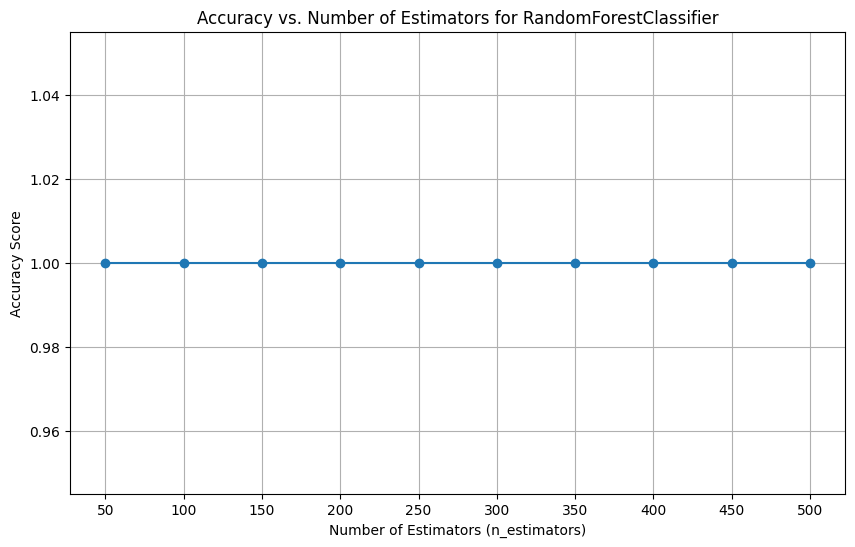

In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

n_estimators_values = []
accuracy_scores = []

for i in range(50,501,50):
    model=RandomForestClassifier(n_estimators=i, random_state=42)
    model.fit(X_train,Y_train)
    y_pred=model.predict(X_test)
    score = accuracy_score(Y_test,y_pred)
    n_estimators_values.append(i)
    accuracy_scores.append(score)
    print(f"{i} {score}")

plt.figure(figsize=(10,6))
plt.plot(n_estimators_values, accuracy_scores, marker='o')
plt.title('Accuracy vs. Number of Estimators for RandomForestClassifier')
plt.xlabel('Number of Estimators (n_estimators)')
plt.ylabel('Accuracy Score')
plt.grid(True)
plt.xticks(n_estimators_values)
plt.show()

Visualization of the trees

In [ ]:
from sklearn.tree import export_graphviz
import pydot

In [ ]:
tree=model.estimators_[10]
export_graphviz(tree,out_file="/content/tree.dot",feature_names=iris.feature_names)

In [ ]:
(graph,)=pydot.graph_from_dot_file("/content/tree.dot")
graph.write_png("/content/trees.png")